In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("/content/AB_NYC_2019.csv")

In [5]:
print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (48895, 16)


In [3]:
print("\nFirst 5 rows:")
display(df.head())


First 5 rows:


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [6]:
df.isnull().sum()

,0
id,0
name,16
host_id,0
host_name,21
neighbourhood_group,0
neighbourhood,0
latitude,0
longitude,0
room_type,0
price,0


In [7]:
df.drop(
    columns=[
        'id',
        'name',
        'host_id',
        'host_name',
        'neighbourhood',
        'last_review'
    ],
    inplace=True
)

In [8]:
print("\nDataset shape:", df.shape)


Dataset shape: (48895, 10)


In [10]:
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

In [11]:
df.isnull().sum()

,0
neighbourhood_group,0
latitude,0
longitude,0
room_type,0
price,0
minimum_nights,0
number_of_reviews,0
reviews_per_month,0
calculated_host_listings_count,0
availability_365,0


<Axes: xlabel='price'>

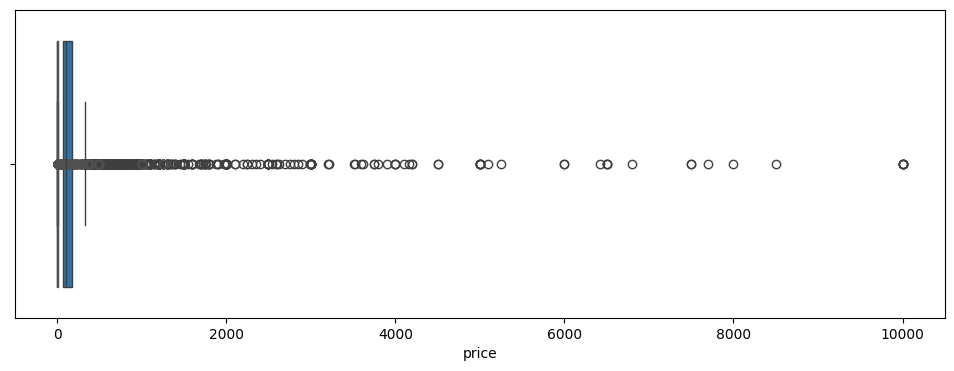

In [13]:
plt.figure(figsize=(12, 4))
sns.boxplot(x=df['price'])

<Axes: xlabel='minimum_nights'>

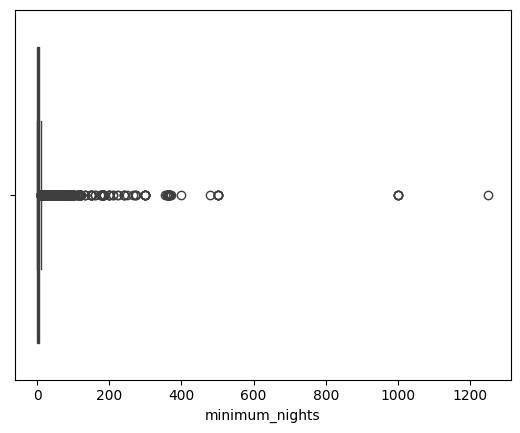

In [14]:
sns.boxplot(x=df['minimum_nights'])

In [15]:
Q1 = df['price'].quantile(0.25)
Q2 = df['price'].quantile(0.50)
Q3 = df['price'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df['price'] = df['price'].clip(lower_bound, upper_bound)

In [16]:
Q1 = df['minimum_nights'].quantile(0.25)
Q2 = df['minimum_nights'].quantile(0.50)
Q3 = df['minimum_nights'].quantile(0.75)

IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df['minimum_nights'] = df['minimum_nights'].clip(
    lower_bound, upper_bound
)

<Axes: xlabel='price'>

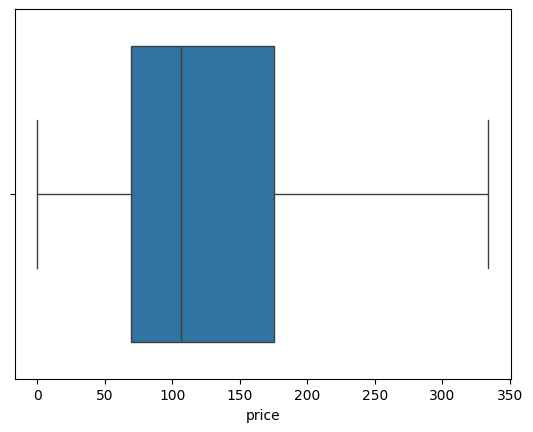

In [17]:
sns.boxplot(x=df['price'])

<Axes: xlabel='minimum_nights'>

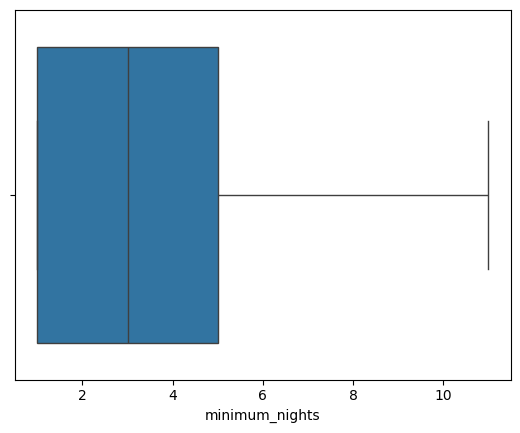

In [18]:
sns.boxplot(x=df['minimum_nights'])

In [19]:
df = pd.get_dummies(
    df,
    columns=['neighbourhood_group', 'room_type'],
    drop_first=True,
    dtype=int
)

df.head()

,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365,neighbourhood_group_Brooklyn,neighbourhood_group_Manhattan,neighbourhood_group_Queens,neighbourhood_group_Staten Island,room_type_Private room,room_type_Shared room
0,40.64749,-73.97237,149,1,9,0.21,6,365,1,0,0,0,1,0
1,40.75362,-73.98377,225,1,45,0.38,2,355,0,1,0,0,0,0
2,40.80902,-73.94190,150,3,0,0.00,1,365,0,1,0,0,1,0
3,40.68514,-73.95976,89,1,270,4.64,1,194,1,0,0,0,0,0
4,40.79851,-73.94399,80,10,9,0.10,1,0,0,1,0,0,0,0


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 14 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   latitude                           48895 non-null  float64
 1   longitude                          48895 non-null  float64
 2   price                              48895 non-null  int64  
 3   minimum_nights                     48895 non-null  int64  
 4   number_of_reviews                  48895 non-null  int64  
 5   reviews_per_month                  48895 non-null  float64
 6   calculated_host_listings_count     48895 non-null  int64  
 7   availability_365                   48895 non-null  int64  
 8   neighbourhood_group_Brooklyn       48895 non-null  int64  
 9   neighbourhood_group_Manhattan      48895 non-null  int64  
 10  neighbourhood_group_Queens         48895 non-null  int64  
 11  neighbourhood_group_Staten Island  48895 non-null  int

In [21]:
X = df.drop('price', axis=1)
y = df['price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)


Features shape: (48895, 13)
Target shape: (48895,)


In [22]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)


Training features: (39116, 13)
Testing features: (9779, 13)
Training target: (39116,)
Testing target: (9779,)


In [23]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [24]:
y_pred = model.predict(X_test)

print("Actual prices:")
print(y_test.head().values)

print("\nPredicted prices:")
print(y_pred[:5])


Actual prices:
[ 89  30 120 334 199]

Predicted prices:
[181.46024953  48.83529759 113.1157671  269.88361477 179.05567275]


In [25]:
results = pd.DataFrame({'Actual': y_test, 'Predicted': y_pred})
print(results)

       Actual   Predicted
879        89  181.460250
44383      30   48.835298
15394     120  113.115767
43230     334  269.883615
16332     199  179.055673
...       ...         ...
20477     215  211.600731
44969     100  147.537884
36577      70   41.506542
11477     334  204.181313
1023      125  145.882798

[9779 rows x 2 columns]


In [27]:

from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)

r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("R-squared:", r2)
print("Mean Absolute Error (MAE):", mae)
print("Mean Squared Error (MSE):", mse)
print("Root Mean Squared Error (RMSE):", rmse)


R-squared: 0.4719189582989599
Mean Absolute Error (MAE): 44.56636179699718
Mean Squared Error (MSE): 3632.429990265627
Root Mean Squared Error (RMSE): 60.2696440197354


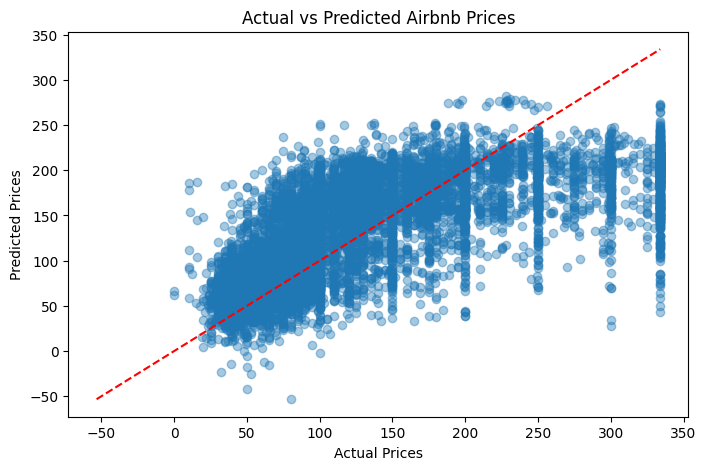

In [28]:

plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.4)

# Perfect prediction line
min_price = min(y_test.min(), y_pred.min())
max_price = max(y_test.max(), y_pred.max())

plt.plot(
    [min_price, max_price],
    [min_price, max_price],
    'r--'
)

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()


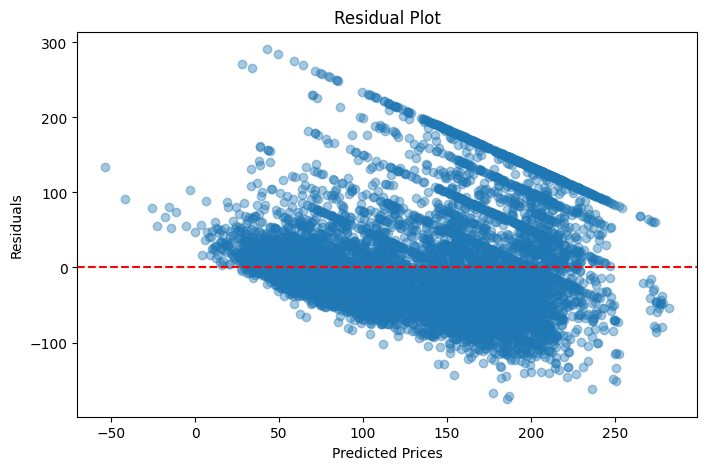

In [29]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

plt.scatter(y_pred, residuals, alpha=0.4)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Plot")
plt.show()
